# **Pre-processing**

## **Libraries**

In [ ]:
import time, os, sys, numpy as np
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch import optim
from torchvision.transforms import transforms
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder
from torchvision.transforms import ToTensor
from torchvision import models
from google.colab import drive
import shutil
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Test if GPU is avaliable, if not, use cpu instead
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
n = torch.cuda.device_count()
devices_ids= list(range(n))
print(device)

cuda


## **Load data into Google Colab**

In [ ]:
# Load FER-2013
!curl -L -o archive.zip https://www.dropbox.com/scl/fi/xwnt5f7ef9lhi8cystbpn/archive.zip?rlkey=5v1kd5kno2bbwi3ewiwzqyzml&dl=0
!unzip archive.zip
# Load KDEF
!curl -L -o kdef.zip https://www.dropbox.com/scl/fi/i72cj2ao0j4z5a74od48b/archive2.zip?rlkey=3b99q9lhu5xbyumtmo0aycsyb&dl=0
!unzip kdef.zip
# FANE
!curl -L -o FANE.zip https://www.dropbox.com/scl/fi/4ix4iu3izscj02xi0iu9w/FANE.zip?rlkey=ckxjmwjxaynfh15xlts8jgyak&dl=0
!unzip FANE.zip

Streaming output truncated to the last 5000 lines.
  inflating: fane_data/sad/sad1736.jpg  
  inflating: fane_data/sad/sad1737.jpg  
  inflating: fane_data/sad/sad1738.jpg  
  inflating: fane_data/sad/sad1739.jpg  
  inflating: fane_data/sad/sad174.jpg  
  inflating: fane_data/sad/sad1740.jpg  
  inflating: fane_data/sad/sad1741.jpg  
  inflating: fane_data/sad/sad1742.jpg  
  inflating: fane_data/sad/sad1743.jpg  
  inflating: fane_data/sad/sad1744.jpg  
  inflating: fane_data/sad/sad1745.jpg  
  inflating: fane_data/sad/sad1746.jpg  
  inflating: fane_data/sad/sad1747.jpg  
  inflating: fane_data/sad/sad1748.jpg  
  inflating: fane_data/sad/sad1749.jpg  
  inflating: fane_data/sad/sad175.jpg  
  inflating: fane_data/sad/sad1750.jpg  
  inflating: fane_data/sad/sad1751.jpg  
  inflating: fane_data/sad/sad1752.jpg  
  inflating: fane_data/sad/sad1753.jpg  
  inflating: fane_data/sad/sad1754.jpg  
  inflating: fane_data/sad/sad1755.jpg  
  inflating: fane_data/sad/sad1756.jpg  
  inflat

In [ ]:
!mkdir kdef
!mv angry/ disgust/ fear/ happy/ neutral/ sad/ surprise/ kdef/
os.rename('/content/kdef/fear', '/content/kdef/fearful')
os.rename('/content/fane_data/fear', '/content/fane_data/fearful')
os.rename('/content/kdef/surprise', '/content/kdef/surprised')
os.rename('/content/fane_data/surprise', '/content/fane_data/surprised')
os.rename('/content/kdef/disgust', '/content/kdef/disgusted')
os.rename('/content/fane_data/disgust', '/content/fane_data/disgusted')
shutil.rmtree('/content/fane_data/shy')
shutil.rmtree('/content/fane_data/confused')

## **Data exploration**

In [ ]:
# Function for plotting bar plot
# dir: direction of a folder to traverse
# title: title of the plot
def plot(dir, title):
  labels = sorted(os.listdir(dir))
  counter = []

  for emotion in labels:
      path = os.path.join(dir, emotion)
      counter.append(len(os.listdir(path)))

  # Create barplot
  sns.barplot(x=labels, y=counter, hue=labels, legend=False, palette='rocket')

  # Set title and labels
  plt.title(title, fontweight ='bold', fontsize = 15)
  plt.xlabel('Labels', fontweight ='bold', fontsize = 12)
  plt.ylabel('Images', fontweight ='bold', fontsize = 12)
  plt.show()

In [ ]:
# Function for displaying images
# dir: direction of a folder to traverse
def expl(dir):
  labels = sorted(os.listdir(dir))
  for i, emotion in enumerate(labels, 1):
      path = os.path.join(dir, emotion)
      img_path = os.path.join(path, os.listdir(path)[0])
      img = plt.imread(img_path)
      plt.subplot(3, 4, i)
      plt.imshow(img, cmap='gray')
      plt.title(emotion)
      plt.axis('off')
  plt.show()

## **Train dataset**

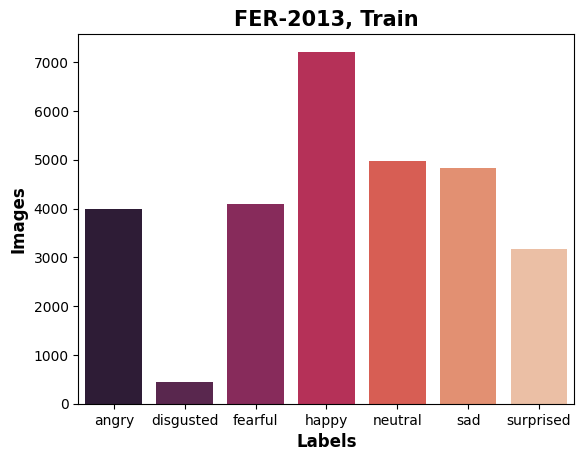

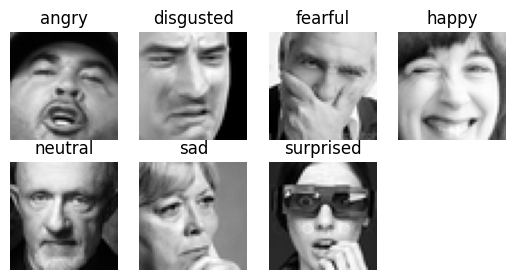

In [ ]:
train_dir = '/content/train/'
plot(train_dir, 'FER-2013, Train')
expl(train_dir)

## **Validation dataset**

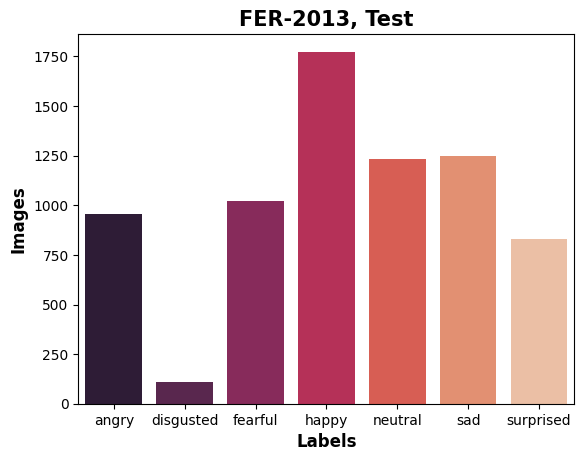

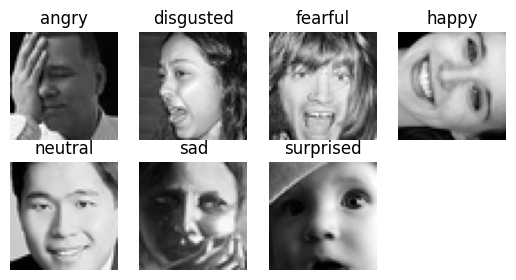

In [ ]:
val_dir = '/content/test/'
plot(val_dir, 'FER-2013, Test')
expl(val_dir)

## **KDEF dataset**

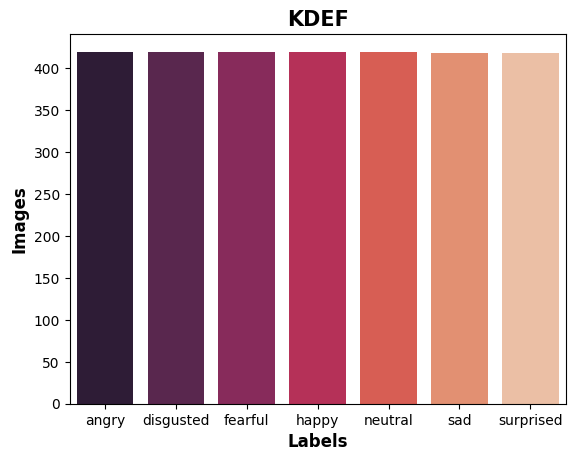

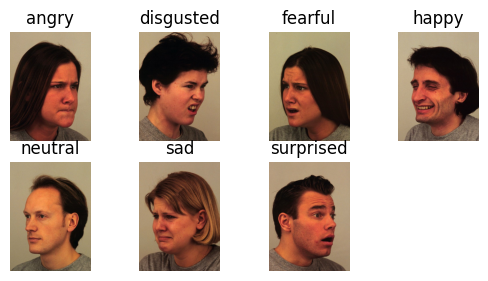

In [ ]:
kdef_dir = '/content/kdef/'
plot(kdef_dir, 'KDEF')
expl(kdef_dir)

## **FANE dataset**

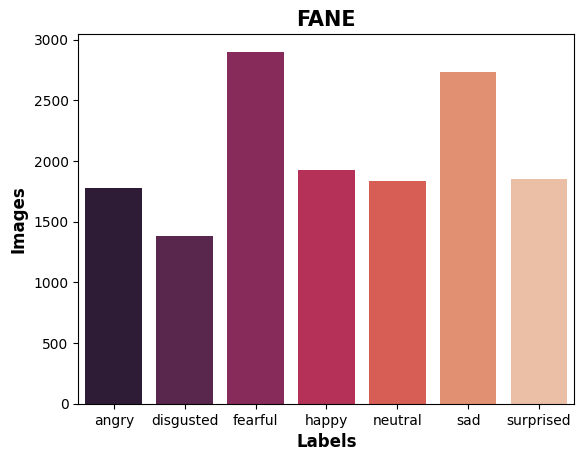

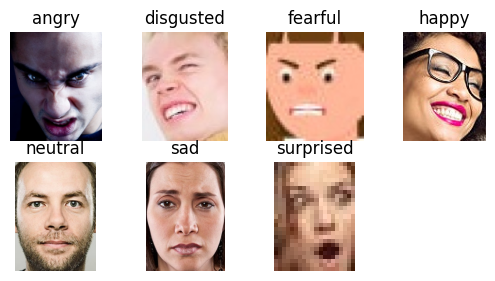

In [ ]:
fane_dir = '/content/fane_data/'
plot(fane_dir, 'FANE')
expl(fane_dir)

## **Transform and load the data**

In [ ]:
#Transforms
train_transformer=transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomAffine((15,90)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),  #0-255 to 0-1, numpy to tensors
    transforms.Normalize(mean=[0.5,0.5,0.5], # 0-1 to [-1,1] , formula (x-mean)/std
                        std=[0.5,0.5,0.5])
])
val_transformer=transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5],
                        std=[0.5,0.5,0.5])
])

#Dataloader
train_dataset = torchvision.datasets.ImageFolder(root=train_dir, transform=train_transformer)
val_dataset = torchvision.datasets.ImageFolder(root=val_dir, transform=val_transformer)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=True)


In [ ]:
#Transforms
test_transformer=transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5,0.5,0.5],
                        std=[0.5,0.5,0.5]),
    transforms.Grayscale(num_output_channels=3)
])


kdef_dataset = torchvision.datasets.ImageFolder(root=kdef_dir, transform=test_transformer)
kdef_loader = DataLoader(kdef_dataset, batch_size=64, shuffle=True)
fane_dataset = torchvision.datasets.ImageFolder(root=fane_dir, transform=test_transformer)
fane_loader = DataLoader(fane_dataset, batch_size=64, shuffle=True)

# **Functions for training and evaluation**

In [ ]:
# Function used to compute accuracy
# data_iter: test/validation dataset
# net: model
# loss: loss function
def evaluate_accuracy(data_iter, net, loss):
    """Evaluate accuracy of a model on the given data set."""

    acc_sum, n, l = torch.Tensor([0]), 0, 0
    net.eval()
    with torch.no_grad():
      for X, y in data_iter:
          X, y = X.to(device), y.to(device)
          y_hat = net(X)
          l += loss(y_hat, y).sum()
          acc_sum += (y_hat.argmax(axis=1) == y).sum().item()
          n += y.size()[0]

    return acc_sum.item() / n, l.item() / len(data_iter)


# Function used for training and network validation
# net: model
# train_iter: training dataset
# test_iter: validation dataset
# trainer: optimizer
# loss: loss function
# num_epochs: the number of epochs
# path: the file name that is saved on drive
def train_validate(net, train_iter, test_iter, batch_size, trainer, loss, num_epochs, path):
    print('training on', device)

    accuracy = []
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(trainer, mode='max', factor=0.1, patience=3)
    best_test_acc = 0.0
    for epoch in range(num_epochs):
        net.train()
        train_l_sum, train_acc_sum, n, start = 0.0, 0.0, 0, time.time()
        for X, y in train_iter:
            X, y = X.to(device), y.to(device)
            y_hat = net(X)
            trainer.zero_grad()
            l = loss(y_hat, y).sum()
            l.backward()
            trainer.step()
            train_l_sum += l.item()
            train_acc_sum += (y_hat.argmax(axis=1) == y).sum().item()
            n += y.size()[0]

        test_acc, test_loss = evaluate_accuracy(test_iter, net, loss)
        scheduler.step(test_acc)
        accuracy.append(test_acc)
        print('epoch %d, train loss %.4f, train acc %.3f, test loss %.4f, '
              'test acc %.3f, time %.1f sec'
              % (epoch + 1, train_l_sum / len(train_iter), train_acc_sum / n, test_loss,
                 test_acc, time.time() - start))

        # Save the model if it achieves a better test accuracy
        if test_acc > best_test_acc:
            best_test_acc = test_acc
            torch.save(net, path)
            print('Saved the model with test accuracy %.3f' % best_test_acc)
            shutil.copy('/content/' + path, '/content/drive/My Drive/' + path)

    print('Training finished. Best test accuracy: %.3f' % best_test_acc)
    return accuracy

# **Load pre-trained models**

In [ ]:
model_vgg16 = models.vgg16(pretrained = True)
model_vgg16.classifier = nn.Sequential(

  nn.Linear(in_features=25088, out_features=4096, bias=True) ,
  nn.ReLU(inplace=True),
  nn.Dropout(p=0.5, inplace=False),
  nn.Linear(in_features=4096, out_features=4096, bias=True),
  nn.ReLU(inplace=True),
  nn.Dropout(p=0.5, inplace=False),

  nn.Linear(in_features=4096, out_features=7, bias=True),
)
model_vgg16

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth
100%|██████████| 528M/528M [00:08<00:00, 65.7MB/s]


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [ ]:
model_vit = models.vit_b_16(pretrained = True)
model_vit

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ViT_B_16_Weights.IMAGENET1K_V1`. You can also use `weights=ViT_B_16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth
100%|██████████| 330M/330M [00:02<00:00, 150MB/s]


VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

In [ ]:
model_vit.heads = nn.Sequential(

  nn.Linear(in_features=768, out_features=7, bias=True),
)
model_vit

VisionTransformer(
  (conv_proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  (encoder): Encoder(
    (dropout): Dropout(p=0.0, inplace=False)
    (layers): Sequential(
      (encoder_layer_0): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
        )
        (dropout): Dropout(p=0.0, inplace=False)
        (ln_2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.0, inplace=False)
          (3): Linear(in_features=3072, out_features=768, bias=True)
          (4): Dropout(p=0.0, inplace=False)
        )
      )
      (encoder_layer_1): EncoderBlock(
        (ln_1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
        (self_a

# **Training and validation**

In [ ]:
vgg16_model = model_vgg16.to(device)
drive.mount('/content/drive')

num_epochs, lr, batch_size, wd_lambda = 8, 0.01, 64, 0.0001
loss = nn.CrossEntropyLoss()
# optimizer setup
trainer = optim.SGD(vgg16_model.parameters(), weight_decay=wd_lambda, lr=lr, momentum=0.9)

# training and validating via Pytorch
vgg16_accuracy = train_validate(vgg16_model, train_loader, val_loader, batch_size, trainer, loss,
                num_epochs, 'vgg16_model.pth')
print(vgg16_accuracy)

Mounted at /content/drive
training on cuda
epoch 1, train loss 1.4846, train acc 0.423, test loss 1.3096, test acc 0.508, time 511.7 sec
Saved the model with test accuracy 0.508
epoch 2, train loss 1.2639, train acc 0.517, test loss 1.2380, test acc 0.536, time 509.8 sec
Saved the model with test accuracy 0.536
epoch 3, train loss 1.1694, train acc 0.554, test loss 1.2239, test acc 0.530, time 510.1 sec
epoch 4, train loss 1.1128, train acc 0.578, test loss 1.1933, test acc 0.552, time 512.4 sec
Saved the model with test accuracy 0.552
epoch 5, train loss 1.0672, train acc 0.597, test loss 1.1951, test acc 0.551, time 511.8 sec
epoch 6, train loss 1.0297, train acc 0.611, test loss 1.1392, test acc 0.565, time 511.2 sec
Saved the model with test accuracy 0.565
epoch 7, train loss 0.9955, train acc 0.626, test loss 1.1567, test acc 0.566, time 512.2 sec
Saved the model with test accuracy 0.566
epoch 8, train loss 0.9664, train acc 0.637, test loss 1.1314, test acc 0.574, time 511.5 sec


'/content/drive/My Drive/vgg16_model.pth'

In [ ]:
drive.mount('/content/drive')
vit_model = model_vit.to(device)

# optimizer setup
trainer = optim.SGD(vit_model.parameters(), lr=lr, weight_decay=wd_lambda, momentum=0.9)

# training and validating via Pytorch
vit_accuracy = train_validate(vit_model, train_loader, val_loader, batch_size, trainer, loss,
                num_epochs, 'vit_model.pth')
print(vit_accuracy)

Mounted at /content/drive
training on cuda
epoch 1, train loss 1.5297, train acc 0.390, test loss 1.3294, test acc 0.494, time 1142.5 sec
Saved the model with test accuracy 0.494
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
epoch 2, train loss 1.1663, train acc 0.552, test loss 1.1598, test acc 0.556, time 1145.3 sec
Saved the model with test accuracy 0.556
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
epoch 3, train loss 1.0562, train acc 0.594, test loss 1.1155, test acc 0.581, time 1145.5 sec
Saved the model with test accuracy 0.581
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
epoch 4, train loss 0.9933, train acc 0.624, test loss 1.0749, test acc 0.588, time 1146.6 sec
Saved the model with test accuracy 0.588
Drive already mounted at /

'/content/drive/My Drive/vit_model.pth'

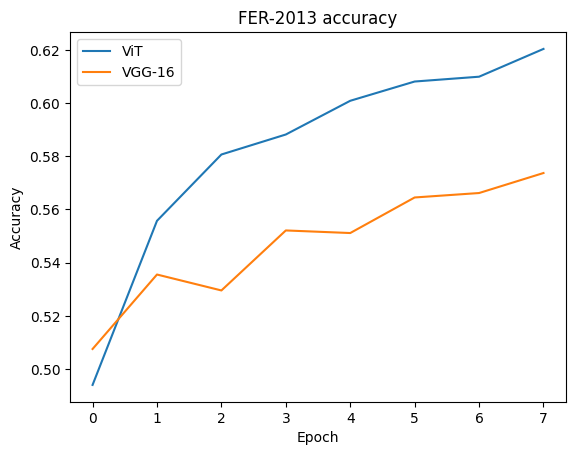

In [ ]:
# Plot
plt.plot(vit_accuracy, label='ViT')
plt.plot(vgg16_accuracy, label='VGG-16')

# Labels and title
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('FER-2013 accuracy')
plt.legend()

plt.show()

In [ ]:
def matrix(net, test_set):
  all_predictions = []
  all_targets = []

  # Iterate through the validation dataset to obtain predictions and ground truth labels
  with torch.no_grad():
      for X, y in test_set:
          X,y = X.to(device), y.to(device)

          # Apply Softmax
          outputs = net(X)
          i, predicted = torch.max(outputs, 1)

          all_predictions.extend(predicted.cpu().numpy())
          all_targets.extend(y.cpu().numpy())

  # Create confusion matrix
  cm = confusion_matrix(all_predictions, all_targets)
  sns.heatmap(cm,
              annot=True,
              fmt='g',
              xticklabels=['angry','disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised'],
              yticklabels=['angry','disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised'])
  plt.ylabel('Prediction',fontsize=13)
  plt.xlabel('Actual',fontsize=13)
  plt.title('Confusion Matrix',fontsize=17)
  plt.show()

# **Class weight balance and training**

In [ ]:
class_weights = []
for root,subdir,files in sorted(os.walk('/content/train')):
  if len(files) > 0:
    class_weights.append(1/len(files))
loss = nn.CrossEntropyLoss(weight=torch.tensor(class_weights).to(device))

In [ ]:
drive.mount('/content/drive')
vit_model_b = model_vit.to(device)

# optimizer setup
trainer = optim.SGD(vit_model_b.parameters(), lr=lr, weight_decay=wd_lambda, momentum=0.9)

# training and validating via Pytorch
vit_accuracy_b = train_validate(vit_model_b, train_loader, val_loader, batch_size, trainer, loss,
                num_epochs, 'vit_model_b.pth')
print(vit_accuracy_b)

Mounted at /content/drive
training on cuda
epoch 1, train loss 1.9353, train acc 0.175, test loss 1.9195, test acc 0.190, time 1083.6 sec
Saved the model with test accuracy 0.190
epoch 2, train loss 1.9198, train acc 0.191, test loss 1.9093, test acc 0.193, time 1094.3 sec
Saved the model with test accuracy 0.193
epoch 3, train loss 1.9106, train acc 0.210, test loss 1.9222, test acc 0.133, time 1094.8 sec
epoch 4, train loss 1.9055, train acc 0.212, test loss 1.9064, test acc 0.194, time 1092.2 sec
Saved the model with test accuracy 0.194
epoch 5, train loss 1.8495, train acc 0.251, test loss 1.7487, test acc 0.321, time 1092.9 sec
Saved the model with test accuracy 0.321
epoch 6, train loss 1.5177, train acc 0.431, test loss 1.5100, test acc 0.418, time 1097.0 sec
Saved the model with test accuracy 0.418
epoch 7, train loss 1.3599, train acc 0.491, test loss 1.4813, test acc 0.461, time 1095.8 sec
Saved the model with test accuracy 0.461
epoch 8, train loss 1.2583, train acc 0.523, t

In [ ]:
drive.mount('/content/drive')
vgg16_model_b = model_vgg16.to(device)

# optimizer setup
trainer = optim.SGD(vgg16_model_b.parameters(), lr=lr, weight_decay=wd_lambda, momentum=0.9)

# training and validating via Pytorch
vgg16_accuracy_b = train_validate(vgg16_model_b, train_loader, val_loader, batch_size, trainer, loss,
                num_epochs, 'vgg16_model_b.pth')
print(vgg16_accuracy_b)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
training on cuda
epoch 1, train loss 1.4445, train acc 0.473, test loss 1.4335, test acc 0.460, time 510.6 sec
Saved the model with test accuracy 0.460
epoch 2, train loss 1.3849, train acc 0.489, test loss 1.4260, test acc 0.510, time 501.1 sec
Saved the model with test accuracy 0.510
epoch 3, train loss 1.3152, train acc 0.513, test loss 1.4020, test acc 0.491, time 501.0 sec
epoch 4, train loss 1.2701, train acc 0.524, test loss 1.3128, test acc 0.492, time 500.5 sec
epoch 5, train loss 1.2335, train acc 0.534, test loss 1.3420, test acc 0.503, time 500.7 sec
epoch 6, train loss 1.2016, train acc 0.547, test loss 1.3362, test acc 0.542, time 500.0 sec
Saved the model with test accuracy 0.542
epoch 7, train loss 1.1659, train acc 0.556, test loss 1.2864, test acc 0.541, time 501.4 sec
epoch 8, train loss 1.1381, train acc 0.568, test loss 1.2510, test acc 0

# **Under-sampling and Training**

In [ ]:
emotions = []
imgs = []
for emotion in sorted(os.listdir("/content/train")):
    emotions.append(emotion)
    imgs.append(len(os.listdir("/content/train/" + emotion)))
emotions_img_dict = {emotions[i]: imgs[i] for i in range(len(emotions))}
for emotion, images in emotions_img_dict.items():
    print(f"{emotion}: {images}")
imapes_per_class = min(imgs)

angry: 3995
disgusted: 436
fearful: 4097
happy: 7215
neutral: 4965
sad: 4830
surprised: 3171


In [ ]:

import random
# Ensure the balanced folder exists or create it if not
if not os.path.exists('/content/train_us'):
    os.makedirs('/content/train_us')

# Iterate over each emotion folder
for emotion_folder in os.listdir('/content/train'):
    emotion_path = os.path.join('/content/train', emotion_folder)

    # Check if it's a directory
    if os.path.isdir(emotion_path):
        images = os.listdir(emotion_path)
        num_images = len(images)
        if num_images >= imapes_per_class:
            selected_images = random.sample(images, imapes_per_class)

            # Create a folder for this emotion
            balanced_class_folder = os.path.join('/content/train_us', emotion_folder)
            if not os.path.exists(balanced_class_folder):
                os.makedirs(balanced_class_folder)

            # Copy selected images to the balanced folder
            for image in selected_images:
                src = os.path.join(emotion_path, image)
                dst = os.path.join(balanced_class_folder, image)
                shutil.copyfile(src, dst)

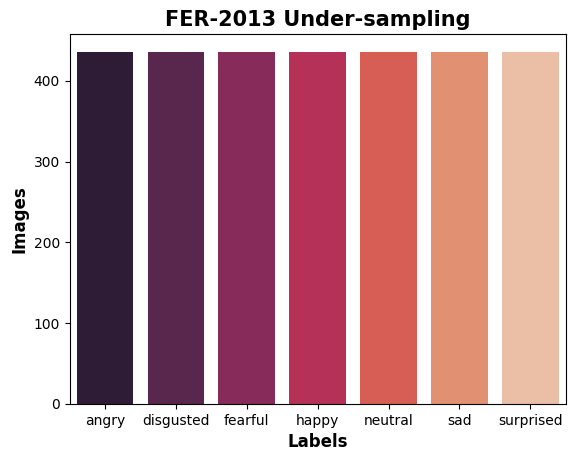

In [ ]:
train_us_dir = '/content/train_us'
plot(train_us_dir, 'FER-2013 Under-sampling')

In [ ]:
#Dataloader
train_dataset_us = torchvision.datasets.ImageFolder(root=train_us_dir, transform=train_transformer)

train_loader_us = DataLoader(train_dataset_us, batch_size=64, shuffle=True)


In [ ]:
drive.mount('/content/drive')
loss = nn.CrossEntropyLoss()
vit_model_us = model_vit.to(device)

# optimizer setup
trainer = optim.SGD(vit_model_us.parameters(), lr=lr, weight_decay=wd_lambda, momentum=0.9)

# training and validating via Pytorch
vit_accuracy_us = train_validate(vit_model_us, train_loader_us, val_loader, batch_size, trainer, loss,
                16, 'vit_model_us.pth')
print(vit_accuracy_us)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
training on cuda
epoch 1, train loss 1.4718, train acc 0.431, test loss 1.5356, test acc 0.410, time 209.7 sec
Saved the model with test accuracy 0.410
epoch 2, train loss 1.3349, train acc 0.480, test loss 1.5286, test acc 0.390, time 211.0 sec
epoch 3, train loss 1.2414, train acc 0.525, test loss 1.3359, test acc 0.486, time 208.8 sec
Saved the model with test accuracy 0.486
epoch 4, train loss 1.1453, train acc 0.568, test loss 1.3181, test acc 0.509, time 209.2 sec
Saved the model with test accuracy 0.509
epoch 5, train loss 1.1091, train acc 0.588, test loss 1.3022, test acc 0.504, time 209.4 sec
epoch 6, train loss 1.0129, train acc 0.629, test loss 1.2975, test acc 0.503, time 209.2 sec
epoch 7, train loss 0.9149, train acc 0.658, test loss 1.3876, test acc 0.503, time 209.3 sec
epoch 8, train loss 0.8671, train acc 0.670, test loss 1.3588, test acc 0

In [ ]:
drive.mount('/content/drive')
loss = nn.CrossEntropyLoss()
vgg16_model_us = model_vgg16.to(device)

# optimizer setup
trainer = optim.SGD(vgg16_model_us.parameters(), lr=lr, weight_decay=wd_lambda, momentum=0.9)

# training and validating via Pytorch
vgg16_accuracy_us = train_validate(vgg16_model_us, train_loader_us, val_loader, batch_size, trainer, loss,
                16, 'vgg16_model_us.pth')
print(vgg16_accuracy_us)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
training on cuda
epoch 1, train loss 1.8894, train acc 0.208, test loss 1.8577, test acc 0.211, time 99.3 sec
Saved the model with test accuracy 0.211
epoch 2, train loss 1.7612, train acc 0.296, test loss 1.7450, test acc 0.278, time 98.3 sec
Saved the model with test accuracy 0.278
epoch 3, train loss 1.6606, train acc 0.356, test loss 1.6737, test acc 0.339, time 98.5 sec
Saved the model with test accuracy 0.339
epoch 4, train loss 1.5619, train acc 0.395, test loss 1.5681, test acc 0.390, time 98.9 sec
Saved the model with test accuracy 0.390
epoch 5, train loss 1.5327, train acc 0.416, test loss 1.5176, test acc 0.421, time 98.0 sec
Saved the model with test accuracy 0.421
epoch 6, train loss 1.4257, train acc 0.460, test loss 1.5323, test acc 0.406, time 97.8 sec
epoch 7, train loss 1.3216, train acc 0.497, test loss 1.3685, test acc 0.482, time 97.4 se

# **Validation dataset testing**

In [ ]:
print('accuracy, loss of ViT model',evaluate_accuracy(val_loader, vit_model,loss))
print('accuracy, loss of VGG-16 model',evaluate_accuracy(val_loader, vgg16_model,loss))
print('accuracy, loss of ViT model balanced with weights',evaluate_accuracy(val_loader, vit_model_b,loss))
print('accuracy, loss of VGG-16 model balanced with weights',evaluate_accuracy(val_loader, vgg16_model_b,loss))
print('accuracy, loss of ViT model using under-sampling for balance ',evaluate_accuracy(val_loader, vit_model_us,loss))
print('accuracy, loss of VGG-16 model using under-sampling for balance ',evaluate_accuracy(val_loader, vgg16_model_us,loss))

accuracy, loss of ViT model (0.6203677904708833, 1.0307461898938743)
accuracy, loss of VGG-16 model (0.5736974087489551, 1.1304650770879425)
accuracy, loss of ViT model balanced with weights (0.515881861242686, 1.2497643664874862)
accuracy, loss of VGG-16 model balanced with weights (0.5671496238506548, 1.1618749567892699)
accuracy, loss of ViT model using under-sampling for balance  (0.5319030370576763, 1.6942881356298396)
accuracy, loss of VGG-16 model using under-sampling for balance  (0.5144887155196434, 1.4341261872148092)


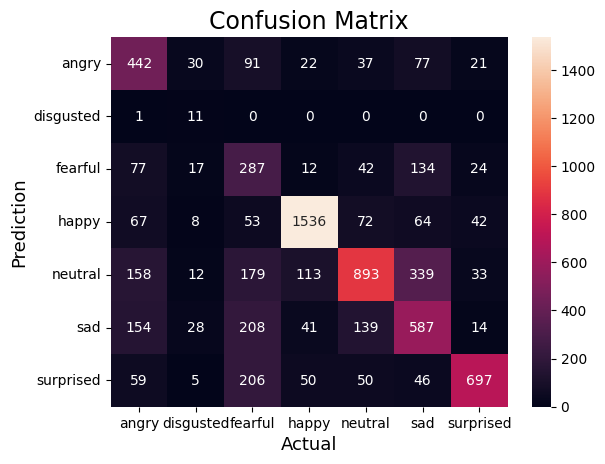

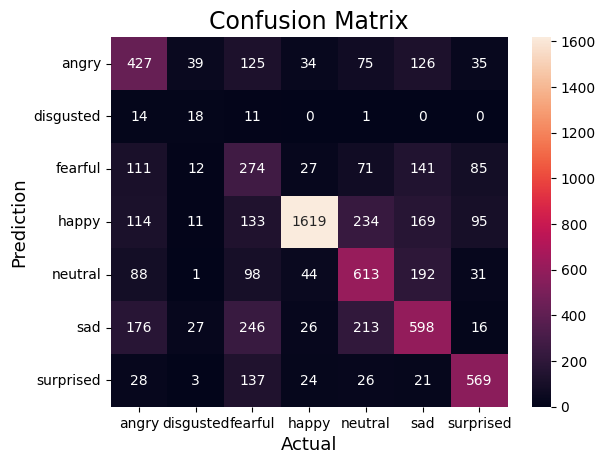

In [ ]:
matrix(vit_model, val_loader)
matrix(vgg16_model, val_loader)

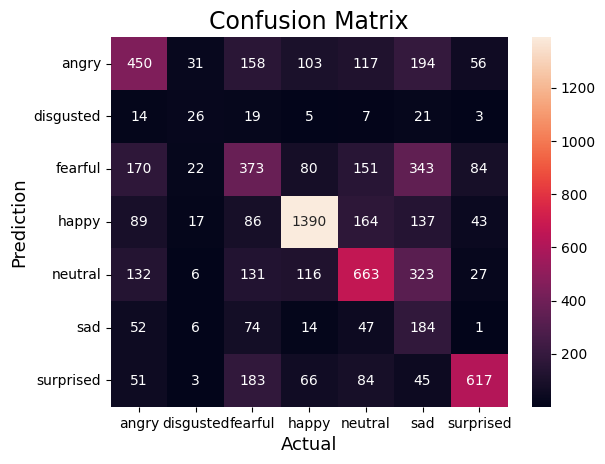

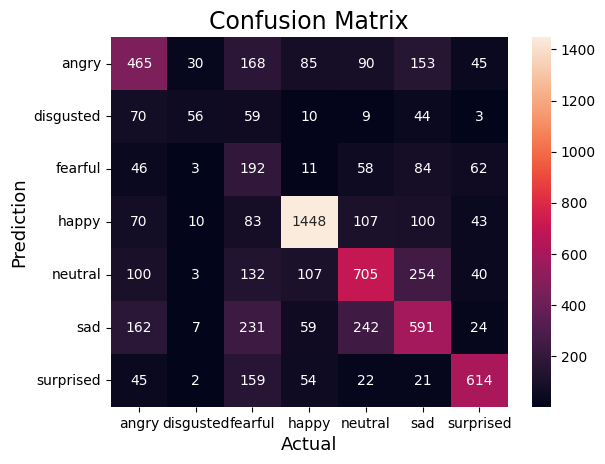

In [ ]:
matrix(vit_model_b, val_loader)
matrix(vgg16_model_b, val_loader)

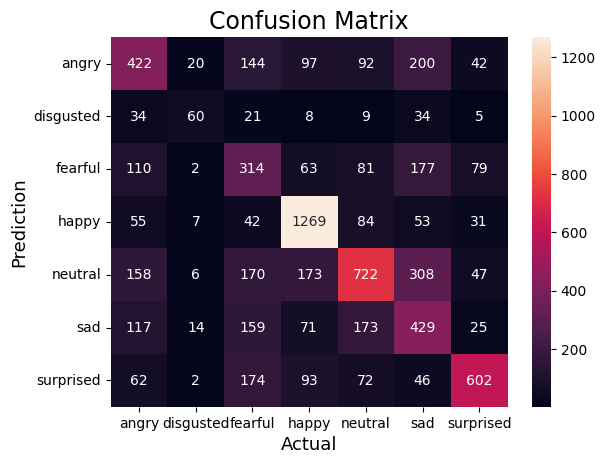

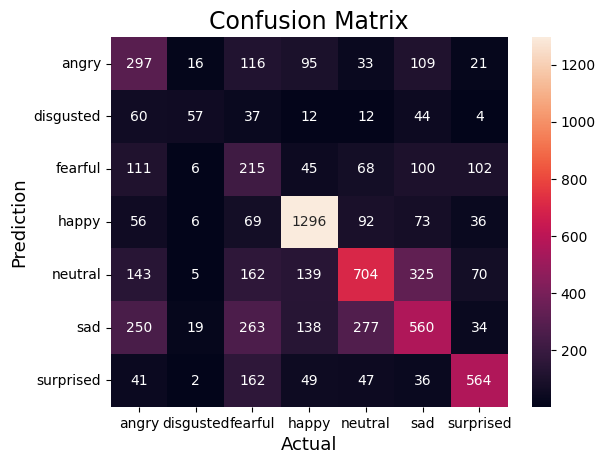

In [ ]:
matrix(vit_model_us, val_loader)
matrix(vgg16_model_us, val_loader)

# **KDEF dataset testing**

In [ ]:
print('accuracy, loss of ViT model',evaluate_accuracy(kdef_loader, vit_model,loss))
print('accuracy, loss of VGG-16 model',evaluate_accuracy(kdef_loader, vgg16_model,loss))
print('accuracy, loss of ViT model balanced with weights',evaluate_accuracy(kdef_loader, vit_model_b,loss))
print('accuracy, loss of VGG-16 model balanced with weights',evaluate_accuracy(kdef_loader, vgg16_model_b,loss))
print('accuracy, loss of ViT model using under-sampling for balance ',evaluate_accuracy(kdef_loader, vit_model_us,loss))
print('accuracy, loss of VGG-16 model using under-sampling for balance ',evaluate_accuracy(kdef_loader, vgg16_model_us,loss))

accuracy, loss of ViT model (0.33083730428863173, 2.668226656706437)
accuracy, loss of VGG-16 model (0.2157930565010211, 2.68805163839589)
accuracy, loss of ViT model balanced with weights (0.28727025187202176, 2.0787809620732847)
accuracy, loss of VGG-16 model balanced with weights (0.291354663036079, 2.6825173419454824)
accuracy, loss of ViT model using under-sampling for balance  (0.34717494894486045, 2.901449783988621)
accuracy, loss of VGG-16 model using under-sampling for balance  (0.2079646017699115, 3.44926585321841)


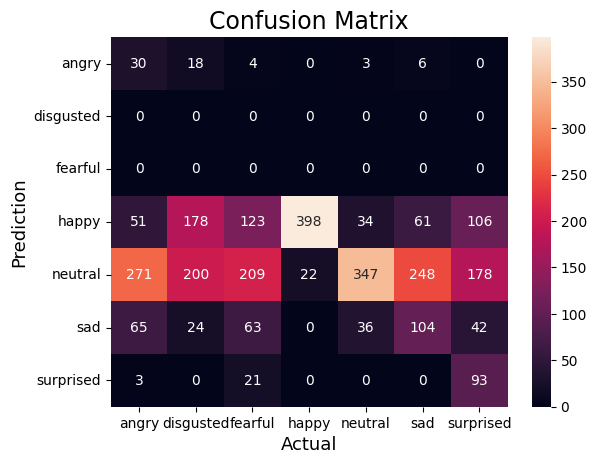

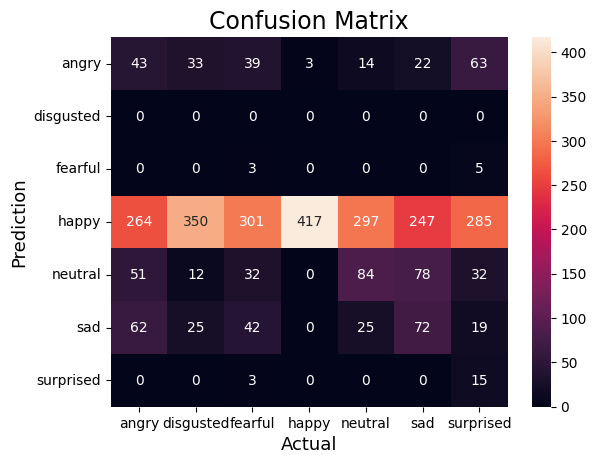

In [ ]:
matrix(vit_model, kdef_loader)
matrix(vgg16_model, kdef_loader)

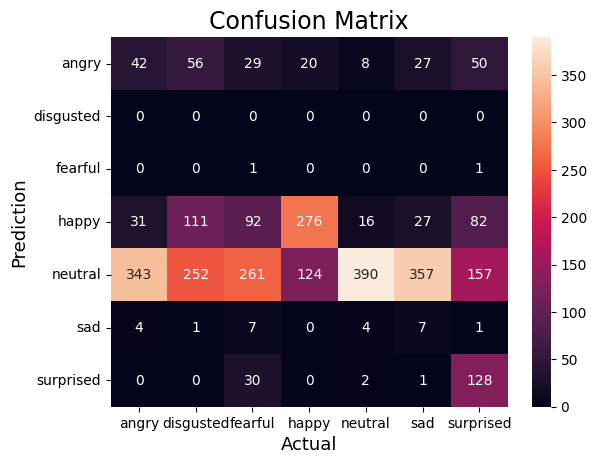

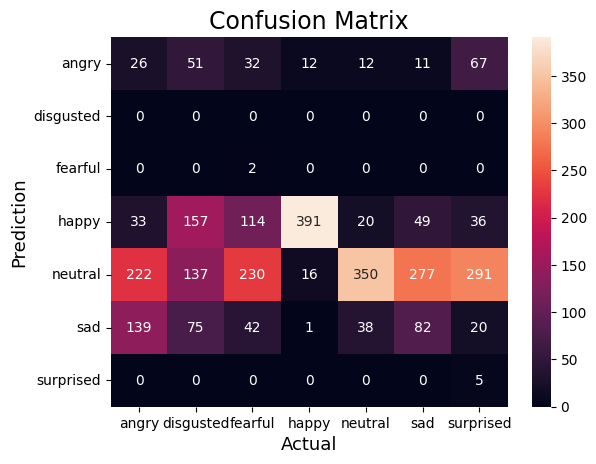

In [ ]:
matrix(vit_model_b, kdef_loader)
matrix(vgg16_model_b, kdef_loader)

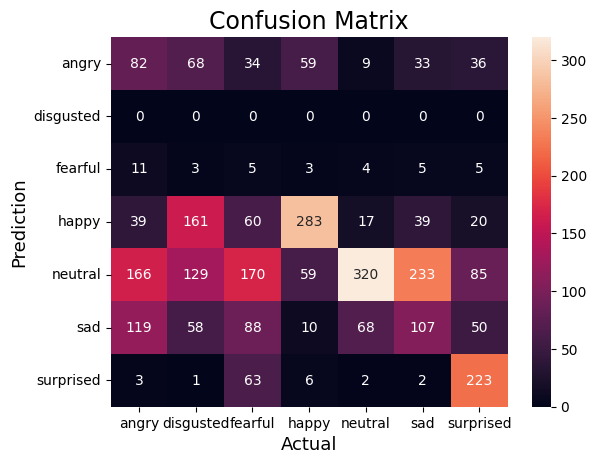

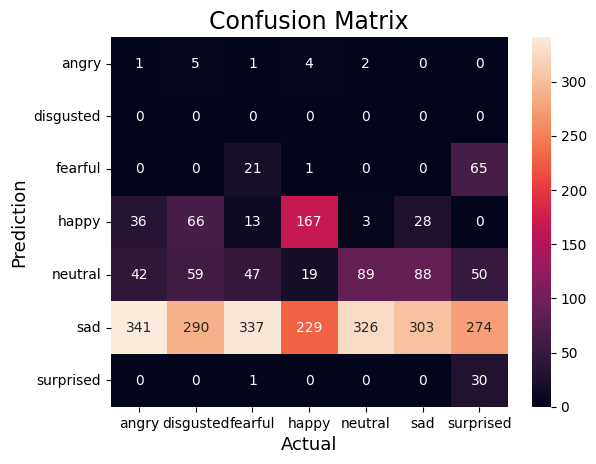

In [ ]:
matrix(vit_model_us, kdef_loader)
matrix(vgg16_model_us, kdef_loader)

# **FANE dataset testing**

In [ ]:
print('accuracy, loss of ViT model',evaluate_accuracy(fane_loader, vit_model,loss))
print('accuracy, loss of VGG-16 model',evaluate_accuracy(fane_loader, vgg16_model,loss))
print('accuracy, loss of ViT model balanced with weights',evaluate_accuracy(fane_loader, vit_model_b,loss))
print('accuracy, loss of VGG-16 model balanced with weights',evaluate_accuracy(fane_loader, vgg16_model_b,loss))
print('accuracy, loss of ViT model using under-sampling for balance ',evaluate_accuracy(fane_loader, vit_model_us,loss))
print('accuracy, loss of VGG-16 model using under-sampling for balance ',evaluate_accuracy(fane_loader, vgg16_model_us,loss))

accuracy, loss of ViT model (0.37341948033903016, 2.1264162868923613)
accuracy, loss of VGG-16 model (0.3327080728081145, 1.9917191569010417)
accuracy, loss of ViT model balanced with weights (0.31985549534528274, 1.7702933756510417)
accuracy, loss of VGG-16 model balanced with weights (0.34361539530359875, 1.8430140516493057)
accuracy, loss of ViT model using under-sampling for balance  (0.3475753786299847, 2.823615993923611)
accuracy, loss of VGG-16 model using under-sampling for balance  (0.32617757398916214, 2.4041172960069446)


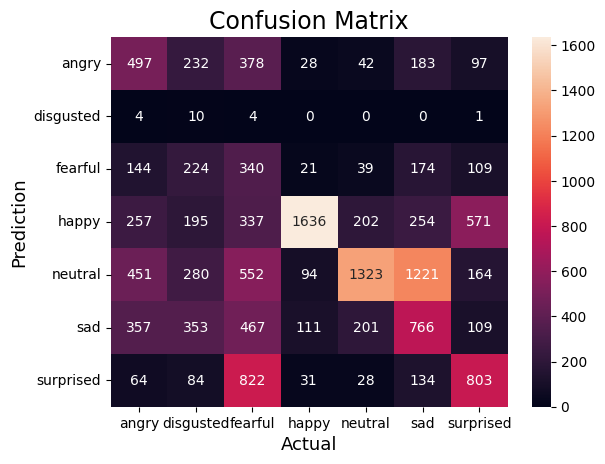

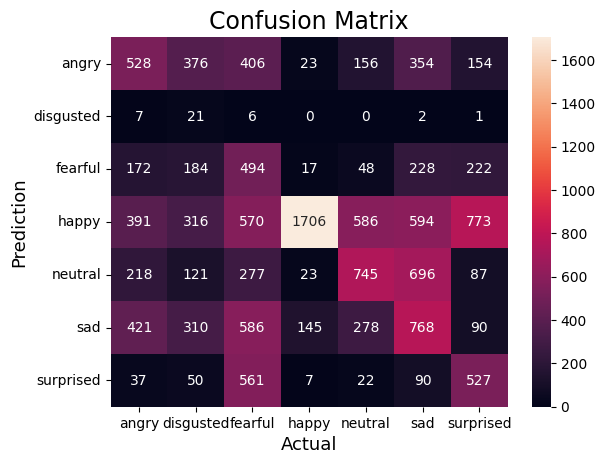

In [ ]:
matrix(vit_model, fane_loader)
matrix(vgg16_model, fane_loader)

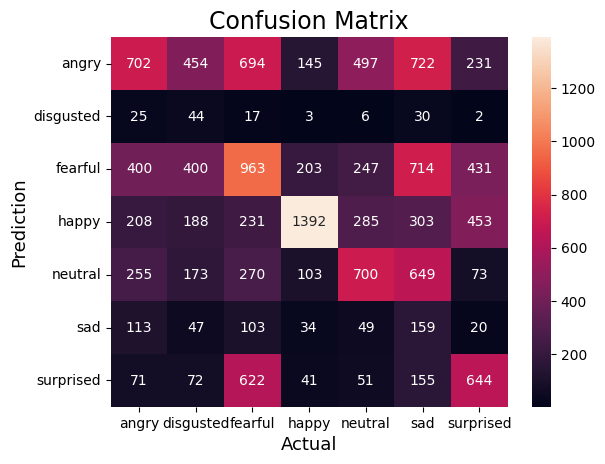

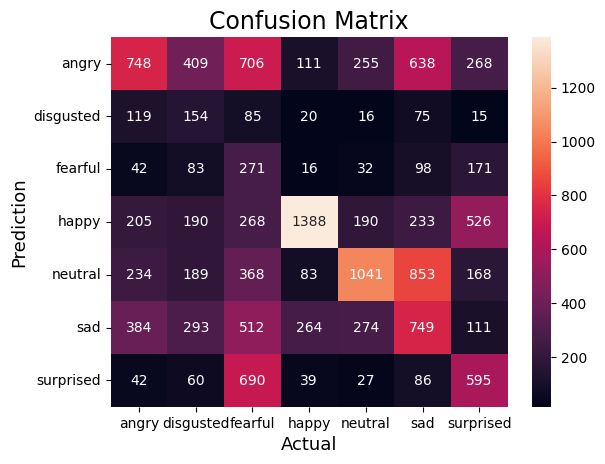

In [ ]:
matrix(vit_model_b, fane_loader)
matrix(vgg16_model_b, fane_loader)

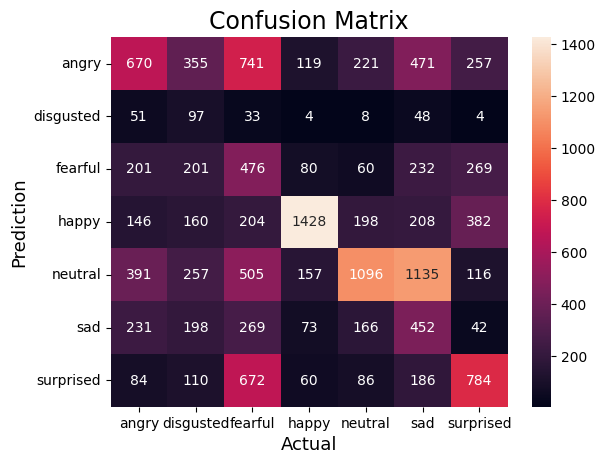

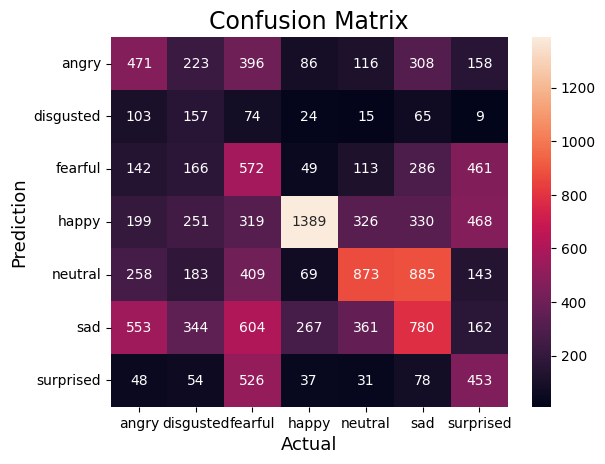

In [ ]:
matrix(vit_model_us, fane_loader)
matrix(vgg16_model_us, fane_loader)